# 01 · Phân tích dữ liệu fine-tune BGE-M3 (Lao động)

Notebook đầu tiên trong `notebooks/finetune/`: **01 phân tích → 02 xử lý → 03 fine-tune**.
Mục tiêu: biết mỗi nguồn dữ liệu đóng góp được gì cho việc dạy BGE-M3 nối *câu hỏi đời thường* với *đoạn luật Pháp điển v5*, và nguồn nào có vấn đề (nhiễu, luật cũ, rò rỉ sang test).

**Nguồn và vị trí** (mỗi nguồn một thư mục, đều gitignored; chi tiết ở `docs/FINETUNE_DATA.md`):

| Nguồn | Dữ liệu thô `data/finetune/` | Đã trích / map `data/processed/finetune/` | Loại câu hỏi |
|---|---|---|---|
| `tvpl` | (stream HF) | `tvpl/tvpl_lao_dong_{train,expanded}.jsonl` | thật (thuvienphapluat) |
| `vlsp` | (stream HF, gated) | `vlsp/vlsp_lao_dong_train.jsonl` | tình huống; đoạn đúng là diễn giải |
| `vilegal` | `vilegal/train_data.json` | `vilegal/vilegal_labor_{mapped,review}.json` | thật (thuvienphapluat) |
| `zalo` | `zalo/train_data_model.json` | `zalo/zaloai_ltr_lao_dong.json` | thật, chữ đã tách từ |
| `bkai` | `bkai/{train,test}.parquet` | — | thật |
| `phamson02` | `phamson02/large_vi_legal_queries.parquet` | — | **sinh tự động (LLM)** |
| `alqac` | `alqac/{corpus,queries,data_ir}/` | — | chuyên gia soạn |

Mọi nguồn được đọc về một dạng chung (`labor_rag/finetune/sources.py`) rồi **gióng về chunk v5** theo n-gram 8 từ (`labor_rag/finetune/align.py`):
**tier A** ≥ 0.5 · **B** 0.1–0.5 · **C** < 0.1; trạng thái thời gian **keep / remap / pending / outside**.

Nội dung: 1. Tổng quan · 2. Độ dài · 3. Mức khớp v5 · 4. Thời gian/hiệu lực · 5. Nhiễu ngoài lĩnh vực · 6. Trùng giữa các nguồn · 7. Rò rỉ sang test · 8. Độ phủ · 9. Kiểm tra ánh xạ ViLegal · 10. Kết luận

In [1]:
import json
import random
import re
import subprocess
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "labor_rag" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from labor_rag.config import (
    EVALUATION_DIR, FINETUNE_MERGED_DIR, FINETUNE_SOURCES, LAO_DONG_DIR,
    finetune_raw_dir, finetune_source_dir,
)

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

# Bảng màu giống notebooks/dataset_analysis.ipynb
INK, INK_SECOND, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_SECOND, "text.color": INK, "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "grid.color": GRID, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
})


def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def stacked_barh(df, title, colors=CAT, figsize=(9, 4)):
    """Horizontal stacked bars, one row per index value, columns as segments."""
    ax = df.plot(kind="barh", stacked=True, color=colors[: len(df.columns)], figsize=figsize, width=0.65)
    ax.invert_yaxis()
    ax.set_title(title, loc="left", color=INK, fontsize=13, pad=10)
    ax.grid(axis="x", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, loc="lower right")
    plt.tight_layout()
    return ax

In [2]:
from labor_rag.finetune import sources
from labor_rag.finetune.align import V5Index, align_record, norm
from labor_rag.finetune.build_dataset import LeakFilter, load_benchmark_questions

index = V5Index.from_jsonl(LAO_DONG_DIR / "chunks.jsonl")
chunks = index.chunks
de_muc = lambda cid: ".".join(chunks[cid]["mapc"].split(".")[:2])

ALIGNED = {}
for name in sources.LOADERS:
    try:
        ALIGNED[name] = [align_record(r, index) for r in sources.load_source(name)]
    except FileNotFoundError as e:
        print(f"[bỏ qua] {name}: thiếu file {e.filename}")
A = pd.DataFrame([r for rows in ALIGNED.values() for r in rows])
A["q_words"] = A["query"].str.split().str.len()
A["p_words"] = A["passage"].fillna("").str.split().str.len()
print(f"Corpus v5: {len(chunks)} chunk, {len(index.documents)} văn bản | bản ghi lao động: {len(A)}")

Corpus v5: 1481 chunk, 153 văn bản | bản ghi lao động: 24661


## 1. Tổng quan từng nguồn

Số bản ghi đã qua lọc từ khoá lao động trên câu hỏi (với nguồn đa lĩnh vực). `exact` = nguồn đã có chunk_id v5 (ViLegal, Zalo, TVPL-v5, VLSP).

In [3]:
overview = A.groupby("source").agg(
    bản_ghi=("qid", "size"),
    câu_hỏi_khác_nhau=("query", lambda s: s.map(norm).nunique()),
    có_đoạn_luật=("passage", lambda s: s.notna().sum()),
    có_exact_id=("exact_chunk_ids", lambda s: s.map(bool).sum()),
    câu_sinh=("is_synthetic", "sum"),
).reindex([s for s in sources.LOADERS if s in ALIGNED])
overview

,bản_ghi,câu_hỏi_khác_nhau,có_đoạn_luật,có_exact_id,câu_sinh
source,,,,,
tvpl,580,471,444,206,0
vlsp,320,320,0,42,0
vilegal,3635,3474,3635,3121,0
zalo,14,14,14,14,0
bkai,7537,7374,7537,0,0
phamson02,12505,12343,12505,0,12505
alqac,70,70,70,0,0


## 2. Độ dài câu hỏi và đoạn luật (số từ)

Chunk v5 dài tối đa ~1000 token. Câu VLSP là tình huống dài; phamson02 và BKAI là câu hỏi ngắn kiểu người dùng.

q_words                                       p_words                                           
             count  mean   std   min   50%   90%    max    count   mean    std    min    50%    90%     max
source                                                                                                     
alqac         70.0  24.0  12.0   4.0  21.0  42.0   57.0     70.0  228.0  173.0   30.0  161.0  394.0   771.0
bkai        7537.0  21.0   6.0   4.0  20.0  29.0   47.0   7537.0  317.0  227.0    7.0  267.0  603.0  2554.0
phamson02  12505.0  28.0   7.0   9.0  27.0  37.0   94.0  12505.0  178.0   41.0  101.0  182.0  230.0   294.0
tvpl         580.0  20.0   7.0   6.0  19.0  28.0   46.0    580.0  174.0  168.0    0.0  144.0  371.0  1365.0
vilegal     3635.0  18.0   6.0   4.0  17.0  26.0   48.0   3635.0  310.0  162.0   23.0  284.0  505.0  1679.0
vlsp         320.0  53.0  16.0  12.0  51.0  75.0  122.0    320.0    0.0    0.0    0.0    0.0    0.0     0.0
zalo          14.0  17.0   5.0  10.0  17.0  22.0   26.0     14.0  164.0   84.0   31.0  155.0  244.0   364.0

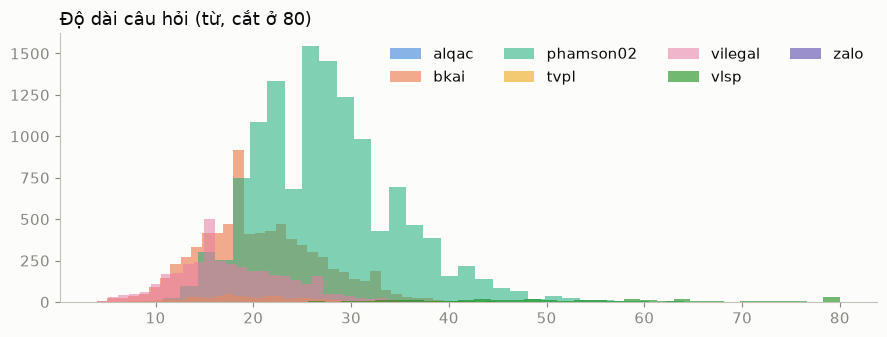

In [4]:
display(A.groupby("source")[["q_words", "p_words"]].describe(percentiles=[.5, .9]).round(0))
fig, ax = plt.subplots(figsize=(9, 3.5))
for i, (name, g) in enumerate(A.groupby("source")):
    ax.hist(g["q_words"].clip(upper=80), bins=40, alpha=0.55, color=CAT[i % len(CAT)], label=name)
ax.set_title("Độ dài câu hỏi (từ, cắt ở 80)", loc="left")
ax.legend(frameon=False, ncol=4)
plt.tight_layout()

## 3. Mức khớp với corpus v5 (tier)

Đây là tiêu chí chính: chỉ cặp nào có đoạn luật **nằm trong v5** mới dùng được làm đoạn đúng (thay bằng text chunk v5 đúng định dạng index).

tier,A,B,C,tỉ_lệ_A
source,,,,
tvpl,366,54,160,0.63
vlsp,0,42,278,0.00
vilegal,3100,417,118,0.85
zalo,13,1,0,0.93
bkai,2973,1101,3463,0.39
phamson02,3894,2094,6517,0.31
alqac,61,0,9,0.87


match,content,exact_rejected,exact_unverified,exact_verified,none
source,,,,,
alqac,66,0,0,0,4
bkai,6176,0,0,0,1361
phamson02,9908,0,0,0,2597
tvpl,330,0,0,206,44
vilegal,502,40,0,3081,12
vlsp,0,0,42,0,278
zalo,0,0,0,14,0


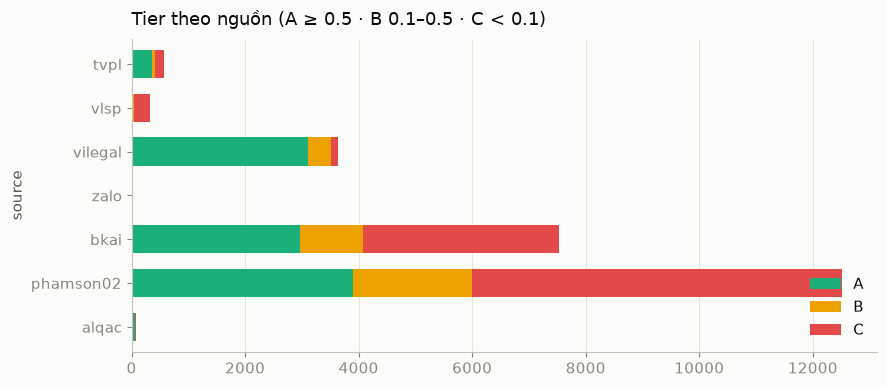

In [5]:
tiers = pd.crosstab(A["source"], A["tier"]).reindex(columns=["A", "B", "C"], fill_value=0)
tiers = tiers.reindex([s for s in sources.LOADERS if s in ALIGNED])
display(tiers.assign(tỉ_lệ_A=(tiers["A"] / tiers.sum(axis=1)).round(2)))
stacked_barh(tiers, "Tier theo nguồn (A ≥ 0.5 · B 0.1–0.5 · C < 0.1)", colors=[CAT[2], CAT[3], CAT[7]])
display(pd.crosstab(A["source"], A["match"]))

## 4. Thời gian / hiệu lực

- **keep**: văn bản được dẫn chính là văn bản của chunk khớp (hoặc không dẫn)
- **remap**: nội dung khớp v5 nhưng nguồn dẫn văn bản khác (bản cũ/sửa đổi) → vẫn dùng, đoạn đúng là chunk v5 hiện hành
- **pending**: không khớp v5, văn bản dẫn ban hành từ 2024 trở đi → có thể *mới hơn* corpus, để chờ cập nhật Pháp điển
- **outside**: không khớp v5 (lĩnh vực khác hoặc luật cũ đã bị thay)

In [6]:
temporal = pd.crosstab(A["source"], A["temporal"]).reindex(columns=["keep", "remap", "pending", "outside"], fill_value=0)
display(temporal.reindex([s for s in sources.LOADERS if s in ALIGNED]))
outside_docs = Counter(d for d in A.loc[(A.tier == "C") & A.cited_doc.notna(), "cited_doc"] if d not in index.documents)
print("Văn bản ngoài v5 hay được dẫn (tier C):")
display(pd.Series(dict(outside_docs.most_common(15)), name="số câu").to_frame())
OLD = r"10-2012-qh13|05-2015-nd-cp|58-2014-qh13|71-2006-qh11"
print("Bản ghi dẫn luật cũ (BLLĐ 2012, NĐ 05/2015, BHXH 2014/2006):",
      A["cited_doc"].fillna("").str.contains(OLD).groupby(A["source"]).sum().to_dict())

temporal,keep,remap,pending,outside
source,,,,
tvpl,420,0,0,160
vlsp,42,0,3,275
vilegal,3517,0,0,118
zalo,14,0,0,0
bkai,3994,80,0,3463
phamson02,4659,1329,0,6517
alqac,61,0,0,9


Văn bản ngoài v5 hay được dẫn (tier C):


,số câu
59-2015-tt-bldtbxh,302
105-2016-ttlt-bqp-bca-bldtbxh,291
57-2015-tt-bldtbxh,182
15-2019-nd-cp,174
136-2020-tt-bqp,170
05-2020-tt-bldtbxh,160
07-2023-tt-bldtbxh,159
143-2016-nd-cp,157
115-2015-nd-cp,156
33-2016-nd-cp,145


Bản ghi dẫn luật cũ (BLLĐ 2012, NĐ 05/2015, BHXH 2014/2006): {'alqac': 0, 'bkai': 7, 'phamson02': 0, 'tvpl': 0, 'vilegal': 0, 'vlsp': 14, 'zalo': 0}


## 5. Nhiễu ngoài lĩnh vực

Câu tier C có từ khoá lao động nhưng đoạn luật không thuộc v5 — ví dụ để thấy nguồn nào nhiễu.

In [7]:
for name in ["bkai", "phamson02", "tvpl", "vlsp"]:
    if name not in ALIGNED:
        continue
    c = A[(A.source == name) & (A.tier == "C")]
    print(f"\n{name}: {len(c)} câu tier C, ví dụ:")
    for q in c["query"].sample(min(6, len(c)), random_state=1):
        print("  -", q[:150].replace("\n", " "))


bkai: 3463 câu tier C, ví dụ:
  - Người bị thiệt hại sẽ được hỗ trợ về an sinh, xã hội, việc làm nếu do sự cố thảm họa gây ra có đúng không?
  - Hồ sơ đề nghị xét chọn học sinh, sinh viên giáo dục nghề nghiệp xuất sắc, tiêu biểu cấp toàn quốc gồm những gì?
  - Viên chức được hưởng các chế độ nào liên quan đến tiền lương?
  - Người lao động phải đăng ký nơi khám chữa bệnh ban đầu theo chỉ định đúng không?
  - Việc bảo đảm điều kiện hoạt động công đoàn đối với cán bộ công đoàn không chuyên trách được quy định như thế nào?
  - Tiền lương để tính trợ cấp một lần của quân nhân chuyên nghiệp khi chuyển sang doanh nghiệp Bộ Quốc phòng là khoản tiền nào?

phamson02: 6517 câu tier C, ví dụ:
  - Người lao động đã có thời gian làm cán bộ cấp xã và được điều động, tuyển dụng vào quân đội nhân dân, công an nhân dân hoặc vào làm việc trong các cơ 
  - Người nào đủ tiêu chuẩn tham dự đánh giá cấp thẻ kiểm định viên chất lượng giáo dục nghề nghiệp?
  - Nếu công chức bị tai nạn lao động, họ có thể lùi

## 6. Trùng câu hỏi giữa các nguồn

TVPL, ViLegal và BKAI đều lấy từ thuvienphapluat nên trùng nhiều; bước 02 khử trùng theo thứ tự ưu tiên ALQAC > ViLegal > TVPL > BKAI > Zalo > VLSP > phamson02.

In [8]:
qsets = {s: set(A.loc[A.source == s, "query"].map(norm)) for s in ALIGNED}
names = list(qsets)
display(pd.DataFrame([[len(qsets[a] & qsets[b]) for b in names] for a in names], index=names, columns=names))
print("Câu hỏi khác nhau sau khi gộp:", len(set().union(*qsets.values())))

,tvpl,vlsp,vilegal,zalo,bkai,phamson02,alqac
tvpl,471,0,130,0,286,0,0
vlsp,0,320,0,0,0,0,0
vilegal,130,0,3474,0,1456,5,0
zalo,0,0,0,14,0,0,0
bkai,286,0,1456,0,7374,5,1
phamson02,0,0,5,0,5,12343,0
alqac,0,0,0,0,1,0,70


Câu hỏi khác nhau sau khi gộp: 22262


## 7. Rò rỉ sang bộ test

So mỗi câu với **mọi** câu benchmark (v1 30 câu, v2 150 câu, v3 200 câu, benchmarks/lao_dong_v5) bằng Jaccard trên tập từ. Ngưỡng loại ở bước 02: ≥ 0.5.

Benchmark: 201 câu


,≥0.5,≥0.6,max
source,,,
alqac,2,2,0.83
bkai,145,37,0.89
phamson02,190,42,0.94
tvpl,15,7,0.75
vilegal,153,45,0.94
vlsp,0,0,0.40
zalo,0,0,0.33


,source,leak_j,query
4473,vilegal,0.944444,Người lao động bị tai nạn lao động cần đáp ứng những điều kiện nào để được hưởng chế độ tai nạn lao động?
14616,phamson02,0.941176,Doanh nghiệp cho thuê lại lao động bị thu hồi giấy phép trong trường hợp nào?
1714,vilegal,0.888889,Người lao động cần đáp ứng những điều kiện gì để được hưởng chế độ tai nạn lao động?
11332,bkai,0.888889,Người lao động cần đáp ứng những điều kiện gì để được hưởng chế độ tai nạn lao động?
4498,vilegal,0.882353,Doanh nghiệp cho thuê lại bị thu hồi giấy phép trong những trường hợp nào?
2154,vilegal,0.833333,Các trường hợp nào doanh nghiệp cho thuê lại lao động bị thu hồi Giấy phép?
24644,alqac,0.833333,Tiền lương của người lao động trong thời gian thử việc do hai bên thỏa thuận nhưng ít nhất phải bằng bao n...
3578,vilegal,0.823529,Những hành vi nào bị nghiêm cấm trong hoạt động an toàn vệ sinh lao động?
14926,phamson02,0.800000,"Người sử dụng lao động có trách nhiệm trả tiền bảo hiểm xã hội, bảo hiểm y tế cho người lao động như thế nào?"
6617,bkai,0.777778,Người lao động làm việc theo ca liên tục từ 6 giờ trở lên thì thời gian nghỉ giữa giờ được tính ra sao?


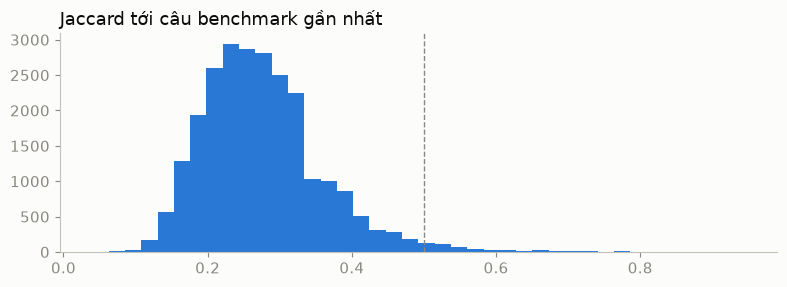

In [9]:
bench = load_benchmark_questions()
leak = LeakFilter(bench, 0.5)
A["leak_j"] = A["query"].map(leak.max_jaccard)
print(f"Benchmark: {len(bench)} câu")
display(A.groupby("source")["leak_j"].agg(**{"≥0.5": lambda s: (s >= .5).sum(), "≥0.6": lambda s: (s >= .6).sum(), "max": "max"}).round(2))
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(A["leak_j"], bins=40, color=CAT[0])
ax.axvline(0.5, color=INK_MUTED, linestyle="--", linewidth=1)
ax.set_title("Jaccard tới câu benchmark gần nhất", loc="left")
plt.tight_layout()
A.sort_values("leak_j", ascending=False)[["source", "leak_j", "query"]].head(10)

## 8. Độ phủ corpus và bộ test

Chỉ tính tier A. `v3 gold` = chunk đáp án của benchmark v3 có câu hỏi train trỏ tới (bình thường, miễn câu hỏi không gần trùng).

In [10]:
v3 = load_jsonl(EVALUATION_DIR / "benchmark_questions_v3.jsonl")
gold = {c for t in v3 for c in t.get("chunk_relevance", {})}
rows = []
for name in ALIGNED:
    cids = {c for r in ALIGNED[name] if r["tier"] == "A" for c in r["positive_chunk_ids"]}
    rows.append({"nguồn": name, "chunk tier A": len(cids), "v3 gold phủ": len(cids & gold),
                 **Counter(de_muc(c) for c in cids if de_muc(c).startswith("20."))})
allA = {c for r in A[A.tier == "A"]["positive_chunk_ids"] for c in r}
rows.append({"nguồn": "GỘP", "chunk tier A": len(allA), "v3 gold phủ": len(allA & gold),
             **Counter(de_muc(c) for c in allA if de_muc(c).startswith("20."))})
cov = pd.DataFrame(rows).set_index("nguồn").fillna(0).astype(int)
print(f"Corpus: {len(chunks)} chunk | v3 gold: {len(gold)} chunk |",
      "chunk theo đề mục:", dict(Counter(de_muc(c) for c in chunks if de_muc(c).startswith("20."))))
cov

Corpus: 1481 chunk | v3 gold: 345 chunk | chunk theo đề mục: {'20.5': 353, '20.4': 423, '20.3': 190, '20.2': 512}


,chunk tier A,v3 gold phủ,20.3,20.2,20.5,20.4
nguồn,,,,,,
tvpl,156,91,7,103,22,24
vlsp,0,0,0,0,0,0
vilegal,546,228,82,301,61,102
zalo,11,3,0,0,3,8
bkai,535,227,86,281,66,102
phamson02,879,278,129,377,150,223
alqac,43,28,0,43,0,0
GỘP,991,307,153,436,153,249


## 9. Kiểm tra ánh xạ ViLegal

Script map của ViLegal gán `chunk_id` = phần đầu `:p1` của Điều; với Điều bị chia nhiều phần, phần khớp thật có thể là `:p2`, `:p3`. Bước gióng chọn phần khớp nhất và loại ánh xạ sai.

In [11]:
if "vilegal" in ALIGNED:
    V = pd.DataFrame(ALIGNED["vilegal"])
    V["first_exact"] = V["exact_chunk_ids"].map(lambda x: x[0] if x else None)
    V["best"] = V["positive_chunk_ids"].map(lambda x: x[0] if x else None)
    multi = V[V["exact_chunk_ids"].map(len) > 1]
    print("Điều nhiều phần:", len(multi), "| phần khớp nhất ≠ p1:", int((multi["first_exact"] != multi["best"]).sum()))
    print("exact bị bác (gióng nội dung sang Điều khác):", int((V["match"] == "exact_rejected").sum()))
    display(V[V["match"] == "exact_rejected"][["query", "first_exact", "best", "score"]].head(8))

Điều nhiều phần: 107 | phần khớp nhất ≠ p1: 43
exact bị bác (gióng nội dung sang Điều khác): 40


,query,first_exact,best,score
15,Đi nghĩa vụ quân sự về có được tiếp tục làm việc tại doanh nghiệp không?,45-2019-qh14:d32,45-2019-qh14:d31,0.8916
64,Có thể giải thể doanh nghiệp khi đang nợ thuế hay không?,45-2019-qh14:d207,NaN,0.0192
213,Hợp đồng lao động song ngữ Anh Việt khi tranh chấp thì ưu tiên áp dụng ngôn ngữ nào?,45-2019-qh14:d15,NaN,0.0455
415,Hợp đồng thử việc bao gồm những nội dung gì?,45-2019-qh14:d24,10-2020-tt-bldtbxh:d3:p1,0.6530
497,Điều kiện hưởng chế độ tai nạn lao động cần đáp ứng những gì?,84-2015-qh13:d45,84-2015-qh13:d48,0.6466
756,Thẩm định hồ sơ vay vốn từ Quỹ quốc gia về việc làm được thực hiện như thế nào?,38-2013-qh13:d29,61-2015-nd-cp:d29,0.9895
796,Nguyên tắc hoạt động cho thuê lại lao động,45-2019-qh14:d54,45-2019-qh14:d53,0.9562
823,Tính trợ cấp thôi việc cho người lao động nước ngoài như thế nào?,38-2013-qh13:d46,145-2020-nd-cp:d8:p1,0.5746


## 10. Kết luận

**Nguồn nào dùng được** (tier A = đoạn luật nằm trong v5):

| Nguồn | Tier A | Nhận xét |
|---|---|---|
| ViLegal | 3,100 / 3,635 (85%) | Nguồn câu hỏi thật tốt nhất, phủ 546 chunk. Ánh xạ exact có 43 câu lấy nhầm `:p1` và 40 câu sai Điều → đã sửa bằng gióng nội dung (vd. "đi nghĩa vụ quân sự về" → Điều 31, không phải 32). |
| BKAI | 2,973 / 7,537 (39%) | Câu hỏi thật, đoạn luật gốc. 3,463 câu tier C là văn bản ngoài Pháp điển Lao động (BQP/BCA, giáo dục nghề nghiệp, BHXH). Trùng 1,456 câu với ViLegal. |
| phamson02 | 3,894 / 12,505 (31%) | Câu **sinh tự động**, phủ rộng nhất (879 chunk, mạnh ở 20.3–20.5). 1,329 câu `remap` (dẫn bản cũ nhưng nội dung = v5). Chỉ dùng bổ sung, giới hạn ≤ 40%. |
| TVPL (Kha) | 366 / 580 | Phần lớn trùng ViLegal/BKAI. |
| ALQAC | 61 / 70 | Chuyên gia soạn, chỉ BLLĐ (20.2). Ít nhưng sạch. |
| Zalo | 13 / 14 | Quá ít; chữ đã được bỏ dấu `_`. |
| VLSP (Kha) | 0 | Đoạn đúng là câu diễn giải, 278/320 dẫn văn bản ngoài v5 → không dùng. |

**Thời gian:** gần như không có luật cũ (BKAI 7, VLSP 14 câu dẫn BLLĐ 2012/NĐ 05/2015…), `pending` (văn bản ≥ 2024 ngoài v5) chỉ 3 câu. Các bộ dữ liệu đều tạo khoảng 2022–2023 nên **không mới hơn** corpus; rủi ro thời gian nằm ở phía corpus (xem `docs/KNOWN_ISSUES.md`).

**Rò rỉ:** ~500 câu có Jaccard ≥ 0.5 với benchmark (ViLegal 153, phamson02 190, BKAI 145) — phải loại trước khi train (bước 02 làm việc này).

**Độ phủ khi gộp tier A:** 991 / 1,481 chunk (20.2: 436, 20.4: 249, 20.3: 153, 20.5: 153), 307 / 345 chunk đáp án của benchmark v3.

→ Notebook **02** gộp, khử trùng, loại rò rỉ, chia train/val theo Điều; notebook **03** fine-tune.